### Imports

In [47]:
!which python
%pip install --upgrade pip
%pip install uproot
%pip install numpy
%pip install pandas
%pip install matplotlib
%pip install torch
%pip install scikit-learn
!source /opt/homebrew/bin/thisroot.sh
!root --version

/Users/krishwu/code/WhitesonAIModelDistinguisher/.venv/bin/python
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
ROOT Version: 6.32.04
Built for macosxarm64 on Aug 14 2024, 03:00:41
From heads/master@tags/v6-32-04


In [49]:
import uproot
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from sklearn import datasets
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix, roc_curve, roc_auc_score, RocCurveDisplay, auc

### Logistic Regression

In [19]:
ptFile = open("data/pt.csv", "r", newline='')
ptyFile = open("data/pty.csv", "r", newline='')

pt = np.genfromtxt(ptFile, delimiter=',')
pty = np.genfromtxt(ptyFile, delimiter=',')

pt = np.array([[item] for item in pt])

pt.shape
pty.shape

(85428,)

In [20]:
# split data
X_train, X_test, y_train, y_test = train_test_split(pt, pty, test_size=0.25, random_state=123)

clf = LogisticRegression(random_state=123)
clf.fit(X_train, y_train)

LogisticRegression(random_state=123)

In [21]:
y_pred = clf.predict(X_test)

acc = accuracy_score(y_test, y_pred)
print("Logistic Regression model accuracy (in %):", acc*100)

Logistic Regression model accuracy (in %): 82.46944795617362


In [37]:
confusion_matrix(y_test, y_pred)

array([[14855,   694],
       [ 3050,  2758]])

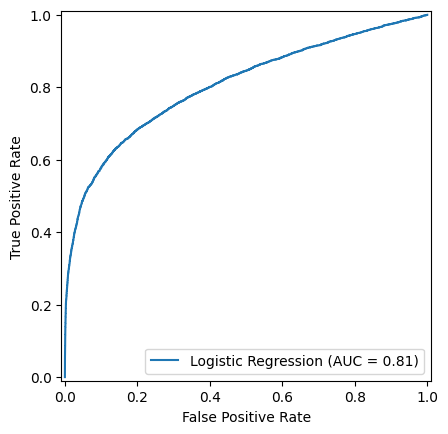

In [50]:
y_prob = clf.predict_proba(X_test)[:, 1]

fpr, tpr, thresholds = roc_curve(y_test, y_prob)

roc_auc = auc(fpr, tpr)

display = RocCurveDisplay(fpr=fpr, tpr=tpr, roc_auc=roc_auc, estimator_name="Logistic Regression")
display.plot()

plt.show()